In [1]:
import numpy as np
import pandas as pd

In [2]:
data=pd.read_csv("insurance.csv")
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,NaN,yes,southwest,16884.92400
1,18,male,NaN,1.0,no,southeast,1725.55230
2,28,male,33.000,3.0,no,southeast,4449.46200
3,33,male,22.705,0.0,no,northwest,21984.47061
4,32,male,28.880,0.0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3.0,no,northwest,10600.54830
1334,18,female,31.920,0.0,no,northeast,2205.98080
1335,18,female,36.850,0.0,no,southeast,1629.83350
1336,21,female,NaN,0.0,no,southwest,NaN


In [3]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,NaN,yes,southwest,16884.92400
1,18,male,NaN,1.0,no,southeast,1725.55230
2,28,male,33.000,3.0,no,southeast,4449.46200
3,33,male,22.705,0.0,no,northwest,21984.47061
4,32,male,28.880,0.0,no,northwest,3866.85520


In [4]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3.0,no,northwest,10600.5483
1334,18,female,31.92,0.0,no,northeast,2205.9808
1335,18,female,36.85,0.0,no,southeast,1629.8335
1336,21,female,NaN,0.0,no,southwest,NaN
1337,61,female,29.07,0.0,yes,northwest,29141.3603


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1333 non-null   float64
 3   children  1337 non-null   float64
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1336 non-null   float64
dtypes: float64(3), int64(1), str(3)
memory usage: 94.5 KB


In [6]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1333.000000,1337.000000,1336.000000
mean,39.207025,30.661223,1.095737,13286.992421
std,14.049960,6.103505,1.205571,12111.490204
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.315000,0.000000,4746.875675
50%,39.000000,30.400000,1.000000,9388.753650
75%,51.000000,34.700000,2.000000,16687.364100
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
missingvalue=data.isnull()
missingvalue

,age,sex,bmi,children,smoker,region,charges
0,False,False,False,True,False,False,False
1,False,False,True,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
1333,False,False,False,False,False,False,False
1334,False,False,False,False,False,False,False
1335,False,False,False,False,False,False,False
1336,False,False,True,False,False,False,True


In [8]:
missingvalue=data.isnull().sum()
missingvalue

age         0
sex         0
bmi         5
children    1
smoker      0
region      0
charges     2
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(1)

In [10]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [11]:
data["bmi"]=data["bmi"].fillna(data["bmi"].mean())
data["children"]=data["children"].fillna(data["children"].mean())

In [12]:
data=data.dropna(subset=["charges"])

In [13]:
data=data.drop_duplicates()

In [14]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [15]:
data.duplicated().sum()

np.int64(0)

In [16]:
data.dtypes

age           int64
sex             str
bmi         float64
children    float64
smoker          str
region          str
charges     float64
dtype: object

In [17]:
print(data['sex'].unique())
print(data['smoker'].unique())
print(data['region'].unique())

<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
<ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [18]:
data = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], dtype=int)

In [19]:
data.head()

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900000,1.095737,16884.92400,1,0,0,1,0,0,0,1
1,18,30.661223,1.000000,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000000,3.000000,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705000,0.000000,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880000,0.000000,3866.85520,0,1,1,0,0,1,0,0


In [20]:
X = data.drop('charges', axis=1)
y = data['charges']

In [21]:
print(X.head())
print(y.head())


   age        bmi  children  sex_female  sex_male  smoker_no  smoker_yes  \
0   19  27.900000  1.095737           1         0          0           1   
1   18  30.661223  1.000000           0         1          1           0   
2   28  33.000000  3.000000           0         1          1           0   
3   33  22.705000  0.000000           0         1          1           0   
4   32  28.880000  0.000000           0         1          1           0   

   region_northeast  region_northwest  region_southeast  region_southwest  
0                 0                 0                 0                 1  
1                 0                 0                 1                 0  
2                 0                 0                 1                 0  
3                 0                 1                 0                 0  
4                 0                 1                 0                 0  
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Na

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1068, 11)
X_test: (267, 11)
y_train: (1068,)
y_test: (267,)


In [24]:
from sklearn.linear_model import LinearRegression

In [25]:
model = LinearRegression()

In [26]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 259.06, 313.39, 607.47,..., 160.31,-688.83,-310.41]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['age','bmi','children',...,'region_northwest','region_southeast', 'region_southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-95.85
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [27]:
print(model)

LinearRegression()


In [28]:
y_pred = model.predict(X_test)

In [29]:
comparison = pd.DataFrame({
    'Actual Charges': y_test,
    'Predicted Charges': y_pred})

print(comparison.head(10))

      Actual Charges  Predicted Charges
900       8688.85885        8596.629259
1064      5708.86700        5522.592697
1255      6474.01300       10315.158685
299       9249.49520       10120.927063
238      17352.68030       26133.334144
482       1622.18850        1666.619260
241       5354.07465        4799.844249
278      12928.79110       13781.102607
416       9140.95100       11476.673008
707      10264.44210       11675.613667


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 4359.05552373756
MSE: 41003919.83139538
RMSE: 6403.4303175247705
R2 Score: 0.7156084434543428


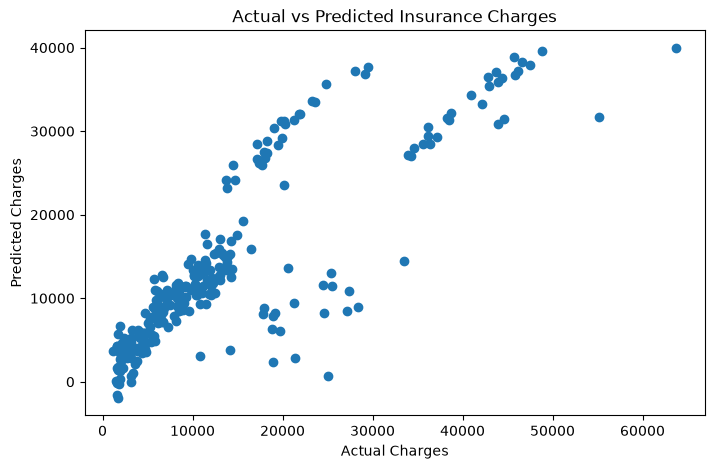

In [31]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()

In [32]:
residuals = y_test - y_pred

print(residuals.head(10))

900       92.229591
1064     186.274303
1255   -3841.145685
299     -871.431863
238    -8780.653844
482      -44.430760
241      554.230401
278     -852.311507
416    -2335.722008
707    -1411.171567
Name: charges, dtype: float64


In [33]:
correlation = data.corr()
print(correlation['charges'].sort_values(ascending=False))

charges             1.000000
smoker_yes          0.787184
age                 0.297147
bmi                 0.196399
region_southeast    0.072806
children            0.066448
sex_male            0.058087
region_northeast    0.006755
region_northwest   -0.039504
region_southwest   -0.042870
sex_female         -0.058087
smoker_no          -0.787184
Name: charges, dtype: float64


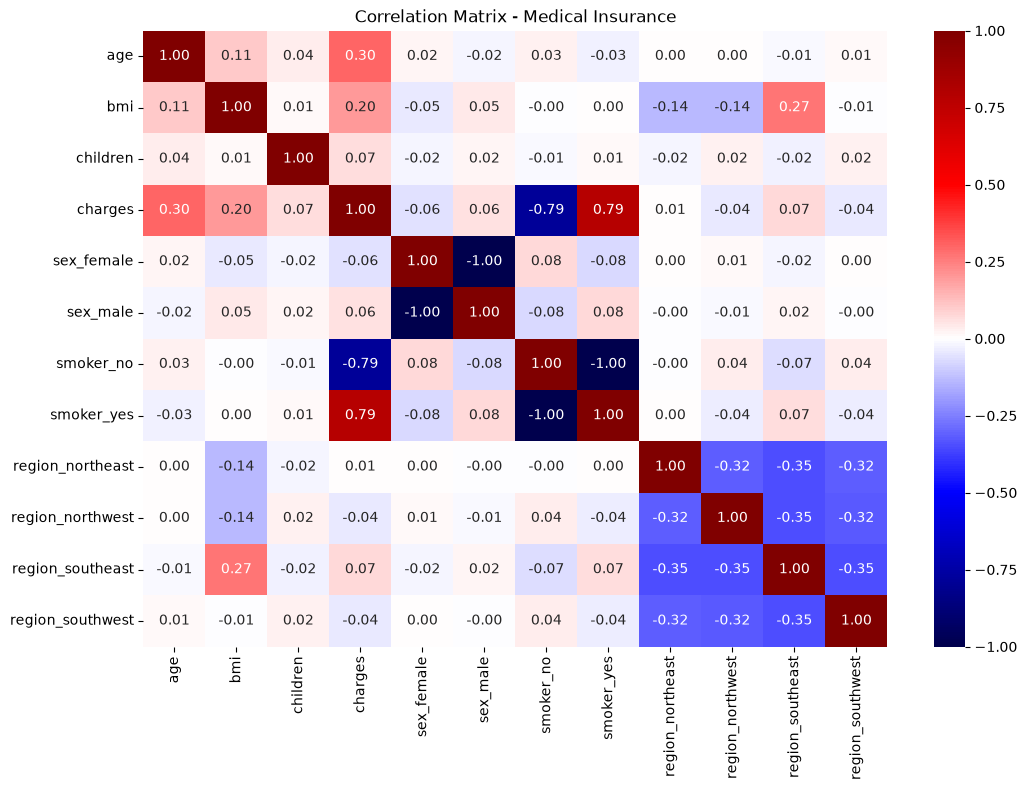

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

sns.heatmap(correlation, annot=True, cmap='seismic', fmt='.2f')

plt.title("Correlation Matrix - Medical Insurance")

plt.show()

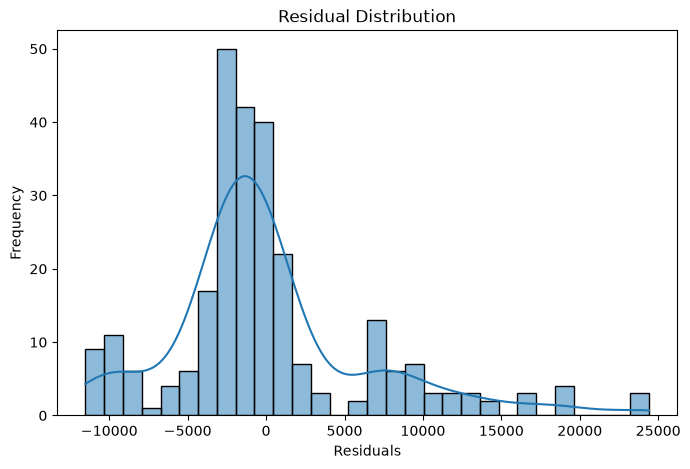

In [37]:
plt.figure(figsize=(8,5))
sns.histplot(residuals, kde=True)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

plt.show()

In [38]:
import joblib

joblib.dump(model, 'insurance_model.pkl')


['insurance_model.pkl']

In [40]:
age = int(input("Enter Age: "))
sex = input("Enter Sex (male/female): ").lower()
bmi = float(input("Enter BMI: "))
children = int(input("Enter Number of Children: "))
smoker = input("Are you a smoker? (yes/no): ").lower()
region = input("Enter Region (northeast/northwest/southeast/southwest): ").lower()

Enter Age:  37
Enter Sex (male/female):  female
Enter BMI:  32
Enter Number of Children:  1
Are you a smoker? (yes/no):  no
Enter Region (northeast/northwest/southeast/southwest):  northwest


In [41]:
new_data = pd.DataFrame([{
    'age': age,
    'bmi': bmi,
    'children': children,
    'sex_female': 1 if sex == 'female' else 0,
    'sex_male': 1 if sex == 'male' else 0,
    'smoker_no': 1 if smoker == 'no' else 0,
    'smoker_yes': 1 if smoker == 'yes' else 0,
    'region_northeast': 1 if region == 'northeast' else 0,
    'region_northwest': 1 if region == 'northwest' else 0,
    'region_southeast': 1 if region == 'southeast' else 0,
    'region_southwest': 1 if region == 'southwest' else 0
}])

new_data = new_data[X.columns]

In [42]:
prediction = model.predict(new_data)

print("Predicted Medical Insurance Charges:", prediction[0])

Predicted Medical Insurance Charges: 8249.052888376631
